# Halo – cosmic-web cross-correlation

The measurement of the paper on one halo mass bin: the isotropic 1D-WCCF and the 3D-WCCF in the local tidal eigenframe, for every web type, for the whole bin and for its early- / late-forming tails (top / bottom 20% in $z_{\rm f}$), with jackknife errors.

For the web cells $c$ of type $W$ (weights $w_c=(1+\delta_c)_+$) and halos $h$,

$$\hat\xi_{\rm Wh}(B)=\frac{1}{\bar n_h V_B}\,\frac{\sum_{c\in W}w_c\,N_h(c,B)}{\sum_{c\in W}w_c}-1,$$

with $B$ a spherical shell (1D) or a bin in the folded eigenframe coordinates $r_i=|(\mathbf{x}_h-\mathbf{x}_c)\cdot\mathbf{e}_i(\mathbf{x}_c)|$, $V_B=8\,\Delta r_1\Delta r_2\Delta r_3$ (3D).

Set `USE_SYNTHETIC = False` and the paths below to run on ELUCID (same code).

In [ ]:
import sys
from pathlib import Path
import pywccf


import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 15, 'axes.titlesize': 14, 'legend.fontsize': 12,
    'axes.linewidth': 1.6, 'legend.frameon': False,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'xtick.major.size': 6, 'ytick.major.size': 6, 'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'xtick.major.width': 1.3, 'ytick.major.width': 1.3,
})

def grid(*axes):
    """Major-tick grid only (line plots)."""
    for ax in axes:
        ax.grid(True, which='major', alpha=0.25, lw=0.7)
        ax.grid(False, which='minor')

def top_legend(fig, handles, labels, ncol=None):
    """Figure legend above the panels, in one row."""
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 1.0),
               ncol=ncol or len(labels), frameon=False)

print('pywccf', pywccf.__version__)

pywccf 0.2.0


## 1. Inputs

In [2]:
from pywccf import TidalField, HaloSample, WCCF1D, WCCF3D, WEB_TYPES, save_results, load_results
from pywccf.core import PAPER_EDGES

USE_SYNTHETIC = True
FIELD_FILE = '/path/to/ELUCID/field_099.2.hdf5'       # R_s = 2, lambda_th = 0
HALO_FILE  = '/path/to/ELUCID/halo_0701.hdf5'
MASS_BIN   = (11.5, 12.0)                              # log(M_h / h^-1 Msun)
TAIL       = 0.2                                       # old / young = top / bottom 20% in z_f
OUT        = Path('output'); OUT.mkdir(exist_ok=True)

if USE_SYNTHETIC:
    from pywccf.utils import synthetic_box
    matter, tf, halos = synthetic_box(n_grids=64, l_box=128.0, n_halos=40_000, R_s=2.0, seed=0)
    edges = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.5, 8.0, 10.0, 12.0])   # node spacing is 2 h^-1 Mpc
    MAX_CELLS, WORKERS = None, 4
else:
    tf = TidalField.from_file(FIELD_FILE, load_evec='lazy')
    halos = HaloSample.from_file(HALO_FILE, l_box=tf.l_box).select_paper()
    matter = None
    edges = PAPER_EDGES                                  # 17 bins incl. the underflow bin [0, 0.5)
    MAX_CELLS, WORKERS = 1_000_000, 8

print(tf)
print('volume fractions:', {k: round(v, 3) for k, v in tf.volume_fractions().items()})

TidalField(Mesh(n_grids=64, l_box=128), keys=('lam', 'delta', 'evec'))
volume fractions: {'void': np.float64(0.089), 'sheet': np.float64(0.454), 'filament': np.float64(0.402), 'knot': np.float64(0.056)}


## 2. Halo samples

In [3]:
halos = halos.subset_by_val('mass', lo=MASS_BIN[0], hi=MASS_BIN[1])
young, old = halos.quantile_masks('zf', TAIL)
samples = {'all': np.ones(len(halos), bool), 'old': old, 'young': young}
print(f'{len(halos):,} halos in [{MASS_BIN[0]}, {MASS_BIN[1]}): {old.sum():,} old, {young.sum():,} young')
print(f"median z_f: old {np.median(halos['zf'][old]):.2f}, young {np.median(halos['zf'][young]):.2f}; "
      f"mean log M_h: old {halos['mass'][old].mean():.3f}, young {halos['mass'][young].mean():.3f}")

22,778 halos in [11.5, 12.0): 4,556 old, 4,556 young
median z_f: old 2.20, young 1.12; mean log M_h: old 11.702, young 11.732


## 3. Measurement

One estimator object per dimension; each `compute(web, samples)` does a single pair-counting pass for all three samples. Errors: delete-one jackknife over $4^3$ sub-cubes of web cells (`'bootstrap'` and `'none'` are also available; the central value is always the deterministic estimator).

In [4]:
kw = dict(edges=edges, max_cells=MAX_CELLS, workers=WORKERS, verbose=False)
w1 = WCCF1D(tf, halos, **kw)          # PH estimator in spherical shells
w3 = WCCF3D(tf, halos, **kw)          # PH estimator in the eigenframe (numba kernel if available)

res1, res3 = {}, {}
for web in WEB_TYPES:
    res1[web] = w1.compute(web, samples, error='jackknife', n_jk_side=4)
    res3[web] = w3.compute(web, samples, error='jackknife', n_jk_side=4)
    c = w3.cells(web)
    print(f'{web:9s} {c.n:>9,} of {c.n_total:,} cells')
res3['filament']['all']

void         23,228 of 23,228 cells


sheet       118,891 of 118,891 cells


filament    105,255 of 105,255 cells


knot         14,770 of 14,770 cells


WCCFResult(3D, web='filament', name='all', method='ph', error='jackknife', shape=(9, 9, 9))

## 4. Directional slices $\xi_{\rm 3D}(r_i)$

`profile(i)` varies $r_i$ with the other two coordinates in their innermost bin (as in the paper); the isotropic $\xi_{\rm 1D}(r)$ is shown for reference. The underflow bin is not drawn.

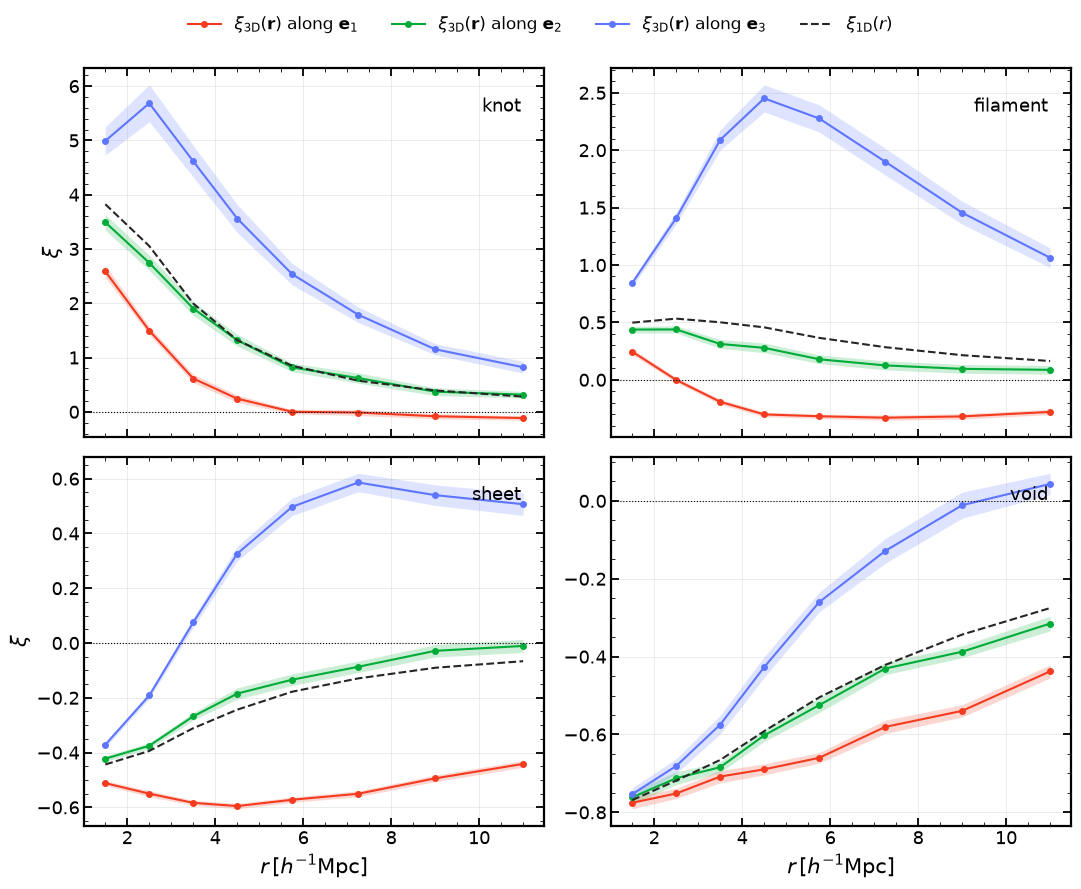

In [5]:
COL = {1: '#f33b1f', 2: '#00ac38', 3: '#5e76ff'}
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True)
for ax, web in zip(axs.flat, WEB_TYPES[::-1]):
    for i in (1, 2, 3):
        r, xi, sd = res3[web]['all'].profile(i)
        ax.plot(r[1:], xi[1:], color=COL[i], marker='o', ms=4)
        ax.fill_between(r[1:], (xi - sd)[1:], (xi + sd)[1:], color=COL[i], alpha=0.2, lw=0)
    r1 = res1[web]['all']
    ax.plot(r1.r[1:], r1.xi[1:], color='0.15', ls='--')
    ax.axhline(0, color='k', lw=0.8, ls=':')
    ax.text(0.95, 0.92, web, transform=ax.transAxes, ha='right', va='top')
    grid(ax)
for ax in axs[1]:
    ax.set_xlabel(r'$r\,[h^{-1}{\rm Mpc}]$')
for ax in axs[:, 0]:
    ax.set_ylabel(r'$\xi$')
fig.tight_layout()
handles = [plt.Line2D([], [], color=COL[i], marker='o', ms=4) for i in (1, 2, 3)] + [plt.Line2D([], [], color='0.15', ls='--')]
top_legend(fig, handles, [rf'$\xi_{{\rm 3D}}(\mathbf{{r}})$ along $\mathbf{{e}}_{i}$' for i in (1, 2, 3)] + [r'$\xi_{\rm 1D}(r)$'])

## 5. Morphology: orthogonal sections of $\xi_{\rm 3D}(\mathbf{r})$
The statistic is measured in the first octant; the panels mirror it into four quadrants for display only (third coordinate in its innermost bin).

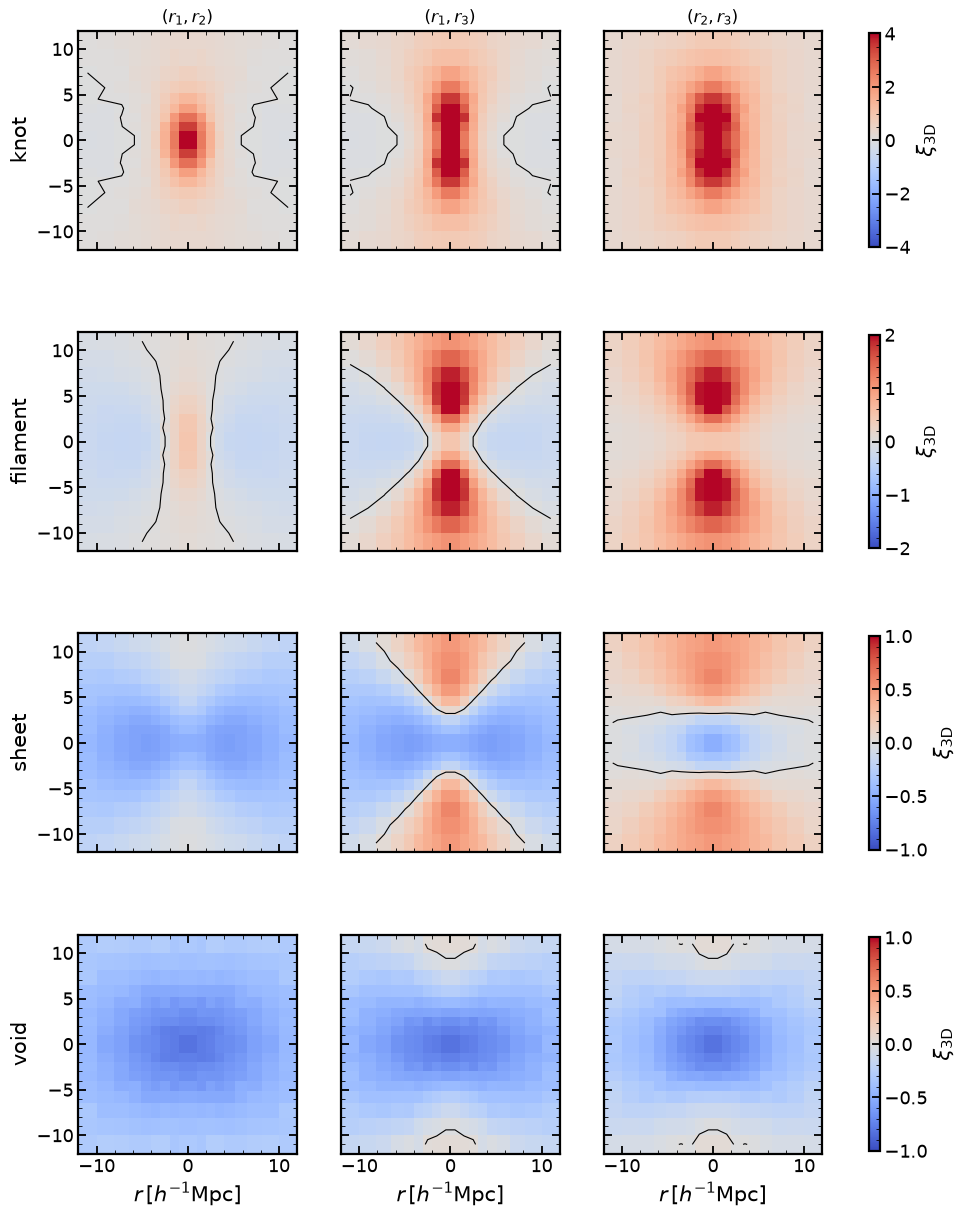

In [6]:
def mirrored(ra, rb, z):
    ra2 = np.concatenate([-ra[::-1], ra]); rb2 = np.concatenate([-rb[::-1], rb])
    z2 = np.block([[z[::-1, ::-1], z[::-1, :]], [z[:, ::-1], z]])
    return ra2, rb2, z2

planes = [(1, 2), (1, 3), (2, 3)]
fig, axs = plt.subplots(4, 3, figsize=(12, 15), sharex=True, sharey=True)
for row, web in zip(axs, WEB_TYPES[::-1]):
    lim = {'knot': 4, 'filament': 2, 'sheet': 1, 'void': 1}[web]
    for ax, (a, b) in zip(row, planes):
        ra, rb, z = res3[web]['all'].plane((a, b))
        X, Y, Z = mirrored(ra, rb, z)
        im = ax.pcolormesh(X, Y, Z.T, cmap='coolwarm', vmin=-lim, vmax=lim, shading='nearest')
        ax.contour(X, Y, Z.T, levels=[0], colors='k', linewidths=0.8)
        ax.set_aspect('equal')
    for ax, (a, b) in zip(row, planes):
        ax.set_title(rf'$(r_{a}, r_{b})$', fontsize=12) if web == 'knot' else None
    row[0].set_ylabel(web)
    fig.colorbar(im, ax=row, shrink=0.85, label=r'$\xi_{\rm 3D}$')
for ax in axs[-1]:
    ax.set_xlabel(r'$r\,[h^{-1}{\rm Mpc}]$')

## 6. Halo age: amplitude ratio $A_W(\mathbf{r})=\xi^{\rm old}_{\rm Wh}/\xi^{\rm young}_{\rm Wh}$

Unstable where $\xi^{\rm young}\to0$; points with $|\xi^{\rm young}|<2\sigma$ are masked. The error is the delete-one jackknife of the ratio itself: both tails were measured in one pass with the same regions, so `samples` of the two results are paired and their covariance is kept.

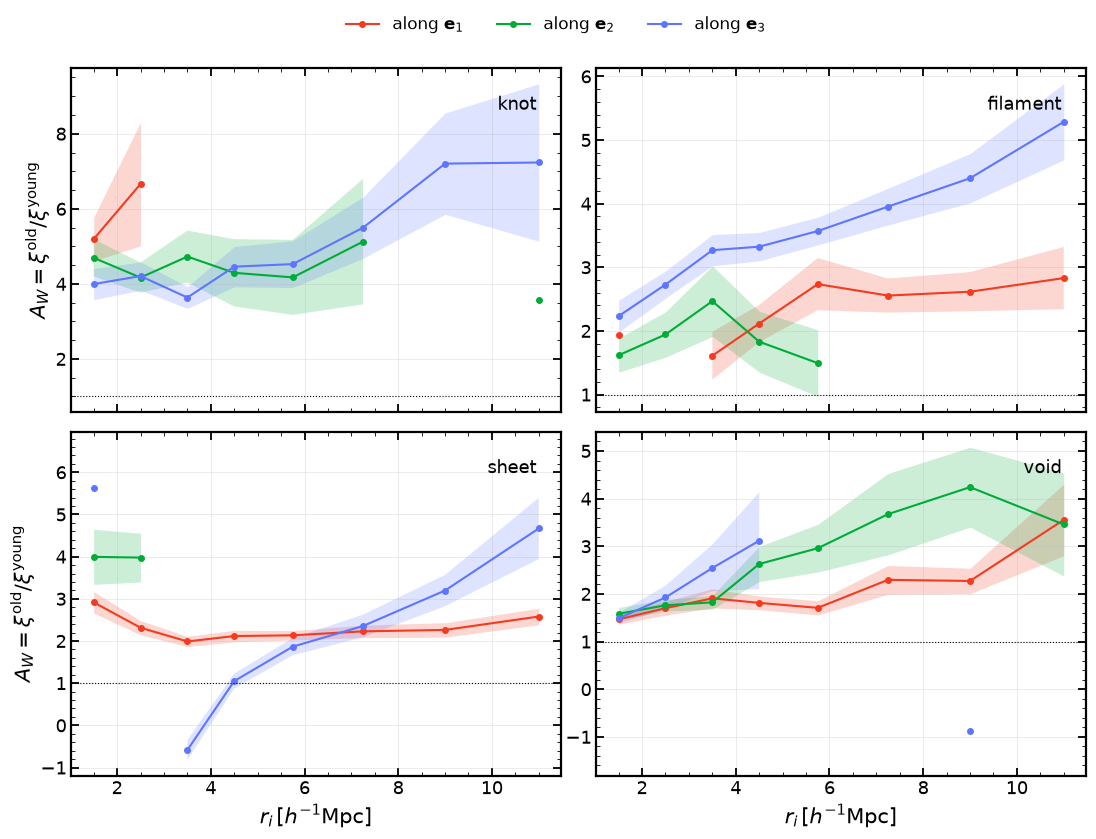

In [7]:
def ratio_profile(web, i, snr=2.0):
    o, y = res3[web]['old'], res3[web]['young']
    r, xo, _ = o.profile(i)
    _, xy, sy = y.profile(i)
    sl = [0, 0, 0]; sl[i - 1] = slice(None)
    sl = (slice(None),) + tuple(sl)
    A_jk = o.samples[sl] / y.samples[sl]
    n = len(A_jk)
    sd = np.sqrt((n - 1) / n * ((A_jk - A_jk.mean(0)) ** 2).sum(0))
    bad = np.abs(xy) < snr * sy
    return r, np.where(bad, np.nan, xo / xy), np.where(bad, np.nan, sd)

fig, axs = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
for ax, web in zip(axs.flat, WEB_TYPES[::-1]):
    for i in (1, 2, 3):
        r, A, sd = ratio_profile(web, i)
        ax.plot(r[1:], A[1:], color=COL[i], marker='o', ms=4)
        ax.fill_between(r[1:], (A - sd)[1:], (A + sd)[1:], color=COL[i], alpha=0.2, lw=0)
    ax.axhline(1, color='k', lw=0.8, ls=':')
    ax.text(0.95, 0.92, web, transform=ax.transAxes, ha='right', va='top')
    grid(ax)
for ax in axs[1]:
    ax.set_xlabel(r'$r_i\,[h^{-1}{\rm Mpc}]$')
for ax in axs[:, 0]:
    ax.set_ylabel(r'$A_W=\xi^{\rm old}/\xi^{\rm young}$')
fig.tight_layout()
top_legend(fig, [plt.Line2D([], [], color=COL[i], marker='o', ms=4) for i in (1, 2, 3)],
           [rf'along $\mathbf{{e}}_{i}$' for i in (1, 2, 3)])

## 7. Matter field: FFT convolution vs. pair counts

With a field as input, `WCCF1D` convolves the web-cell weight field with the field's overdensity (FFT) and averages over the grid displacements of each shell. A tracer can take the same route (`method='fft'`: first assigned to the tidal mesh with CIC), a cross-check of the pair counts that agrees beyond a few cell sizes. The web–matter correlation sets the scale of the halo one ($\xi_{\rm Wh}\simeq b\,\xi_{\rm Wm}$ on large scales).

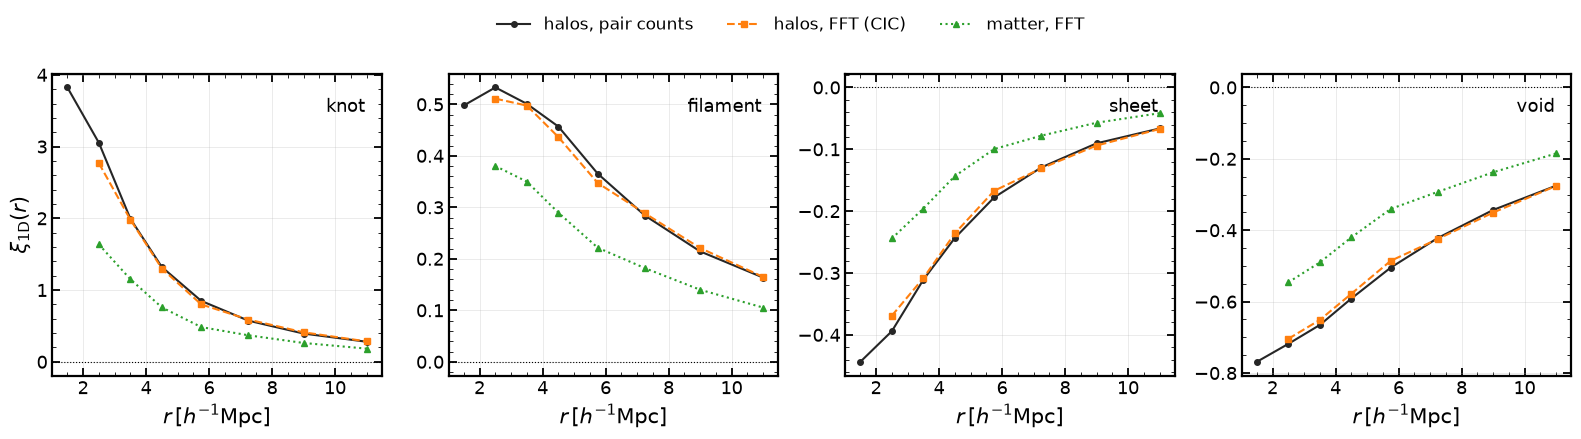

In [8]:
if matter is not None:
    w1_m   = WCCF1D(tf, field=matter, edges=edges, verbose=False)                      # field: FFT
    w1_fft = WCCF1D(tf, halos, edges=edges, method='fft', scheme='cic', verbose=False)  # halos via CIC + FFT
    fig, axs = plt.subplots(1, 4, figsize=(16, 4))
    for ax, web in zip(axs, WEB_TYPES[::-1]):
        m = w1_m.compute(web, error='none')['all']
        f = w1_fft.compute(web, error='none')['all']
        p = res1[web]['all']
        ax.plot(p.r[1:], p.xi[1:], 'o-', color='0.15', ms=4)
        ax.plot(f.r[1:], f.xi[1:], 's--', color='C1', ms=4)
        ax.plot(m.r[1:], m.xi[1:], '^:', color='C2', ms=4)
        ax.axhline(0, color='k', lw=0.8, ls=':')
        ax.text(0.95, 0.92, web, transform=ax.transAxes, ha='right', va='top')
        ax.set_xlabel(r'$r\,[h^{-1}{\rm Mpc}]$')
        grid(ax)
    axs[0].set_ylabel(r'$\xi_{\rm 1D}(r)$')
    fig.tight_layout()
    top_legend(fig, axs[0].lines[:3], ['halos, pair counts', 'halos, FFT (CIC)', 'matter, FFT'])

## 8. Save and reload

In [9]:
path = OUT / ('halo_web_synthetic.h5' if USE_SYNTHETIC else f'halo_web_m{MASS_BIN[0]}_{MASS_BIN[1]}.h5')
results = {web: {f'1d_{k}': v for k, v in res1[web].items()} | {f'3d_{k}': v for k, v in res3[web].items()}
           for web in WEB_TYPES}
save_results(path, results, run_info={'mass_bin': list(MASS_BIN), 'tail': TAIL, 'R_s': tf.R_s,
                                      'lambda_th': tf.lam_th, 'synthetic': USE_SYNTHETIC})
back = load_results(path)
print(path, '|', sorted(back['filament']), '|', back['run'])
r, xi, sd = back['filament']['3d_old'].profile(3)
print('filament, old, xi_3D along e3:', xi[1:5].round(3))

output/halo_web_synthetic.h5 | ['1d_all', '1d_old', '1d_young', '3d_all', '3d_old', '3d_young'] | {'R_s': 2.0, 'lambda_th': 0.0, 'mass_bin': array([11.5, 12. ]), 'synthetic': True, 'tail': 0.2}
filament, old, xi_3D along e3: [1.12  2.094 3.241 3.962]
